# Atajo de la máscara y clasificador temprana/tardía por variante

Segunda parte de la elección de la variante de imágenes (capa/bandas del visor de Legacy Survey),
después del filtro de calidad y fuga norte/sur de `notebook/image-curation.ipynb` (sección 6). Ver
`README.md`, sección "Elegir la variante de imágenes".

1. **Atajo de la máscara.** ¿La silueta de la máscara, sin nada de la galaxia, ya predice
   temprana/tardía? Si sí, un modelo entrenado con imágenes enmascaradas puede aprender el contorno
   recortado en vez de la estructura.
2. **Clasificador binario temprana/tardía** con cada variante, original y enmascarada. Se usa un
   *linear probe*: una ResNet-34 de ImageNet **congelada** extrae 512 features por imagen y una
   regresión logística clasifica. Al no entrenar el backbone, la única diferencia entre corridas es
   el dataset, así que la comparación es justa y rápida. No es el modelo final (ver `README.md`,
   sección "Arquitectura del modelo").
3. **Rendimiento por región y generalización norte ↔ sur.**

Lógica en `src/`: `src/models/linear_probe.py`, `src/evaluate.py` (`predictability_test`,
`out_of_fold_proba`, `bootstrap_auc_ci`, `paired_bootstrap_auc_diff`, `cross_group_auc`) y
`src/data/galaxy_mask.py` (`mask_shape_features`, `mask_silhouette`).

> **Muestra chica:** 50 galaxias (25 tempranas / 25 tardías). Los intervalos de confianza serán
> anchos y diferencias pequeñas entre variantes no serán significativas. Para la decisión real,
> ampliar la muestra (`python -m src.data.download_cutouts --variants all --n 2000`) y volver a
> ejecutar esta libreta sin cambios.

### Guía de lectura para no especialistas en IA

**La pregunta.** Tenemos 50 galaxias ya clasificadas a ojo por astrónomos (`Ttype`) como *tempranas*
(elípticas/lenticulares) o *tardías* (espirales/irregulares). De cada una bajamos la imagen de
Legacy Survey en 8 versiones ("variantes": distinto data release —DR9, DR10, DR11— y distinta
combinación de bandas —g, r, i, z—). Queremos saber **con qué versión de la imagen una computadora
distingue mejor una temprana de una tardía**, para usar esa versión al entrenar el modelo final.

**Cómo "mira" la computadora.** Usamos una red neuronal (ResNet-34) que ya fue entrenada con
millones de fotos cotidianas (perros, coches, paisajes). No la volvemos a entrenar: la usamos como
un instrumento fijo que convierte cada imagen en 512 números que resumen texturas, formas,
contrastes y colores. Después, una fórmula sencilla (regresión logística) aprende a separar
tempranas de tardías con esos 512 números. Es parecido a medir parámetros fijos de cada galaxia
(índice de Sérsic, concentración, color) y trazar una frontera entre las dos poblaciones, solo que
aquí los parámetros los define la red y no un astrónomo.

> **Nota: ¿qué datos usa el modelo?** Solo la **imagen en color** (los recortes `.jpg` RGB del visor
> de Legacy Survey, originales o enmascarados), igual que una persona mirando el visor. No recibe
> medidas físicas: ni espectros MaNGA, ni archivos `.fits` calibrados, ni columnas del catálogo
> (fotometría, redshift, etc.). Otros datos intervienen, pero no como entrada:
>
> - el **`Ttype`** de `data/morfologia.csv` da la respuesta correcta (temprana/tardía) contra la que
>   se califica al modelo;
> - **`PETRO_TH90`** fija el zoom de cada recorte para que todas las galaxias tengan un tamaño
>   aparente parecido (ver `src/data/legacy_cutouts.py`); el modelo no ve ese número;
> - la **región norte/sur** solo se usa para separar galaxias en la evaluación de la sección 3.
>
> Además, en esta libreta **la red neuronal no se entrena**: está congelada y solo traduce cada
> imagen a 512 números. Lo único que aprende es la fórmula final (regresión logística).

**Por qué la comparación es justa.** El "instrumento" y la fórmula son siempre los mismos; lo único
que cambia entre corridas es la imagen. Si una variante sale mejor, es por la imagen.

**Evaluación honesta.** El modelo siempre se califica con galaxias que **no vio** al aprender (como
reservar una submuestra de control). Nunca se califica con las mismas galaxias con las que se ajustó.

**La calificación principal: AUC.** Va de 0.5 a 1. Si tomamos al azar una tardía y una temprana, el
AUC es la probabilidad de que el modelo diga correctamente cuál de las dos es la tardía.
**0.5 = lanzar una moneda; 1.0 = nunca se equivoca al ordenarlas.** Como guía: 0.7 es una señal débil,
0.9 es buena y 0.95 o más es muy buena.

**Dos versiones de cada imagen.** *Original* (el recorte tal cual) y *enmascarada* (solo la galaxia
central, con el resto en negro). La máscara quita estrellas y vecinas, pero el contorno que deja
podría delatar la clase por sí solo. La sección 1 revisa ese riesgo.

**Cautela.** Con 50 galaxias los resultados son preliminares: sirven para descartar opciones malas,
no para elegir con precisión entre opciones parecidas.

In [1]:
# importaciones de sistema
import sys
import warnings
from pathlib import Path

# Referencia a otros archivos sin necesidad de instalar el paquete
PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# importaciones de librerias de terceros
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, f1_score

warnings.filterwarnings("ignore", category=UserWarning)  # avisos de sklearn/torch en paralelo

In [2]:
# configuracion de proyecto
from src.config import (
    CUTOUTS_INDEX_CSV,
    EARLY_TYPE_LABEL,
    LATE_TYPE_LABEL,
    LEGACY_REGION_NORTH,
    LEGACY_REGION_SOUTH,
    MORFOLOGIA_LABEL_TO_INT,
    PROBE_REFERENCE_VARIANT,
    SHORTCUT_AUC_ALERT,
    SHORTCUT_LOGREG_C,
    SHORTCUT_P_VALUE_MAX,
)
from src.data.galaxy_mask import mask_cutout, mask_silhouette
from src.data.image_quality import (
    SHAPE_FEATURES,
    build_variant_feature_table,
    quality_flags,
    region_color_gap,
)
from src.evaluate import (
    bootstrap_auc_ci,
    cross_group_auc,
    out_of_fold_proba,
    paired_bootstrap_auc_diff,
    predictability_test,
)
from src.models.linear_probe import build_backbone, embed_cutouts, make_logistic_probe
from src.utils import set_seed

set_seed()

# Colores fijos por entidad (paleta categórica validada, slots 1 y 2).
CLASS_COLORS = {EARLY_TYPE_LABEL: "#eb6834", LATE_TYPE_LABEL: "#2a78d6"}
INPUT_COLORS = {"original": "#2a78d6", "enmascarada": "#eb6834"}

features = build_variant_feature_table(pd.read_csv(CUTOUTS_INDEX_CSV))
variants = list(features["variante"].cat.categories)

# Filtro 1 (notebook/image-curation.ipynb, sección 6): mismo criterio, recalculado aquí.
flags = quality_flags(features)
passes_filter_1 = (
    (flags["con_zona_sin_cobertura"] == 0)
    & (flags["mascara_vacia"] == 0)
    & ~region_color_gap(features)["color_heterogeneo"]
)
print(f"{features['name'].nunique()} galaxias x {len(variants)} variantes")
display(passes_filter_1.rename("pasa_filtro_1").to_frame().T)

50 galaxias x 8 variantes


variante,ls-dr9_grz,ls-dr10_grz,ls-dr10_griz,ls-dr10_gri,ls-dr10-grz_grz,ls-dr11_grz,ls-dr11_griz,ls-dr11_gri
pasa_filtro_1,True,False,True,False,True,True,True,True


**Lectura del resultado (para no especialistas).** La tabla dice qué variantes pasaron el control de
calidad previo (`notebook/image-curation.ipynb`, sección 6): sin zonas sin datos, con máscara
válida y con **el mismo aspecto de color en el norte y en el sur del cielo**. Las galaxias del norte
las observaron BASS/MzLS (Kitt Peak) y las del sur DECam (Chile), y algunas variantes las
colorean distinto según la región.

- **Pasan (`True`):** 6 de las 8 variantes.
- **No pasan (`False`):** `ls-dr10_grz` (las galaxias del sur salen moradas) y `ls-dr10_gri` (las
  del sur salen verdosas). Con dos "estilos" de color, un modelo podría aprender a reconocer el
  telescopio en lugar de la morfología.

**Conclusión:** las 8 variantes se evalúan igual en esta libreta para poder compararlas, pero las
dos que no pasan quedan descartadas como candidatas.

## 1. Atajo de la máscara

### 1.1 Silueta media por clase

Promedio de las máscaras de cada clase en la variante de referencia: dónde suele cubrir la máscara
de una temprana y de una tardía. La diferencia (derecha) muestra si una clase tiene, en promedio,
máscaras más grandes o de otra forma.

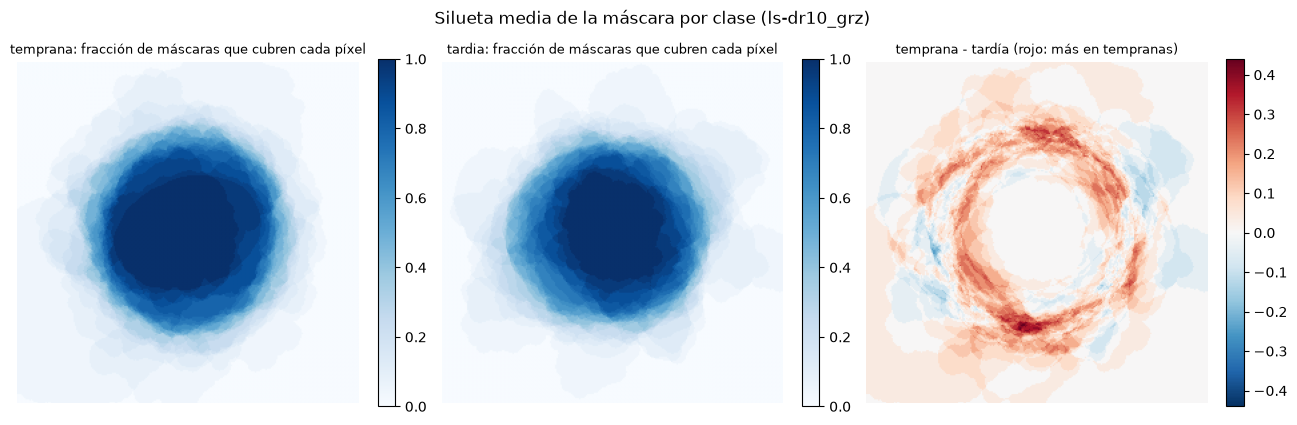

,mask_frac,elongacion,compacidad,solidez
label,,,,
tardia,0.248,0.342,0.692,0.96
temprana,0.282,0.219,0.719,0.96


In [3]:
def variant_masks(variant):
    """Máscaras booleanas (n, H, W) de una variante, en orden de nombre."""
    subset = features[features["variante"] == variant].sort_values("name")
    layer, bands = subset[["layer", "bands"]].iloc[0]
    return np.stack([mask_cutout(name, layer, bands)[1] for name in subset["name"]]), subset


ref_masks, ref_subset = variant_masks(PROBE_REFERENCE_VARIANT)
mean_mask = {label: ref_masks[(ref_subset["label"] == label).to_numpy()].mean(axis=0)
             for label in (EARLY_TYPE_LABEL, LATE_TYPE_LABEL)}
difference = mean_mask[EARLY_TYPE_LABEL] - mean_mask[LATE_TYPE_LABEL]

fig, axes = plt.subplots(1, 3, figsize=(13, 4.3))
for ax, label in zip(axes[:2], (EARLY_TYPE_LABEL, LATE_TYPE_LABEL)):
    im = ax.imshow(mean_mask[label], cmap="Blues", vmin=0, vmax=1)
    ax.set_title(f"{label}: fracción de máscaras que cubren cada píxel", fontsize=9)
    fig.colorbar(im, ax=ax, fraction=0.046)
limit = np.abs(difference).max()
im = axes[2].imshow(difference, cmap="RdBu_r", vmin=-limit, vmax=limit)
axes[2].set_title("temprana - tardía (rojo: más en tempranas)", fontsize=9)
fig.colorbar(im, ax=axes[2], fraction=0.046)
for ax in axes:
    ax.axis("off")
fig.suptitle(f"Silueta media de la máscara por clase ({PROBE_REFERENCE_VARIANT})")
plt.tight_layout()
plt.show()

display(features[features["variante"] == PROBE_REFERENCE_VARIANT]
        .groupby("label")[SHAPE_FEATURES].mean().round(3))

**Lectura de la figura (para no especialistas).** La máscara marca qué píxeles pertenecen a la
galaxia central. Aquí se promedian las máscaras de las 25 tempranas (izquierda) y las 25 tardías
(centro):

- **Azul oscuro** = píxeles que casi todas las máscaras cubren (el centro de la galaxia); se aclara
  hacia afuera porque cada galaxia tiene un tamaño distinto.
- Los dos promedios se ven **redondos** aunque haya galaxias alargadas, porque cada galaxia está
  orientada a su manera y al promediar se compensan.
- **Derecha (diferencia):** rojo = zonas que cubren más a menudo las máscaras de tempranas; azul =
  las de tardías. El **anillo rojo** indica que las máscaras de las tempranas llegan un poco más
  lejos del centro, es decir, son algo más grandes. El centro blanco significa que ambas clases lo
  cubren siempre.

**Tabla:** promedio de 4 descriptores de forma de la máscara por clase.

- `mask_frac` (fracción de la imagen que ocupa la máscara): 0.28 en tempranas vs. 0.25 en
  tardías. Las tempranas son algo más grandes en el recorte.
- `elongacion`: 0.34 en tardías vs. 0.22 en tempranas. Las tardías son más alargadas, lo esperado
  para discos vistos de canto o inclinados.
- `compacidad` y `solidez`: casi iguales; las dos clases tienen contornos igual de "llenos" y regulares.

**Conclusión:** el contorno de la máscara sí difiere un poco entre clases, sobre todo en tamaño y
elongación, y esas diferencias tienen sentido físico. La siguiente celda mide si basta con el
contorno para adivinar la clase.

### 1.2 ¿La silueta sola predice la clase?

Para cada variante, AUC (validación cruzada estratificada 5×10, p-valor por 200 permutaciones) de
una regresión logística que predice *tardía* usando **solo** la máscara:

- **descriptores de forma** (4 números: área, elongación, compacidad, solidez);
- **silueta** reducida a 32×32 px (1,024 valores: forma y tamaño completos del contorno).

Lectura: AUC ≈ 0.5 → la máscara no delata la clase. AUC alta y significativa → hay atajo; comparar
con el AUC del clasificador sobre la imagen enmascarada (sección 2): si se parecen, ese modelo
podría estar usando sobre todo el contorno.

**Términos de esta sección**

- **Regresión logística:** modelo lineal que, a partir de las features, da una probabilidad entre
  0 y 1 de que la galaxia sea *tardía*. Es deliberadamente simple: si con un modelo así la máscara
  ya predice la clase, el atajo existe. Con features $\mathbf{x}$, pesos $\mathbf{w}$ y sesgo $b$
  aprendidos (con regularización L2 de fuerza $1/C$):

  $$\hat p = P(\text{tardía}\mid\mathbf{x}) = \sigma(\mathbf{w}^\top\mathbf{x} + b)
  = \frac{1}{1 + e^{-(\mathbf{w}^\top\mathbf{x} + b)}}$$
- **AUC (área bajo la curva ROC):** probabilidad de que, tomando al azar una tardía y una temprana,
  el modelo le dé mayor probabilidad de *tardía* a la tardía. 0.5 = azar (no distingue), 1.0 =
  separa perfecto, < 0.5 = peor que azar. No depende de ningún umbral ni del balance de clases,
  por eso se usa como métrica principal (ver `README.md`, sección "Métricas de evaluación").
  Con $n_+$ tardías (probabilidades $\hat p_i$) y $n_-$ tempranas ($\hat p_j$):

  $$\mathrm{AUC} = \frac{1}{n_+\,n_-}\sum_{i\,\in\,\text{tardías}}\;\sum_{j\,\in\,\text{tempranas}}
  \Big[\mathbb{1}(\hat p_i > \hat p_j) + \tfrac{1}{2}\,\mathbb{1}(\hat p_i = \hat p_j)\Big]$$

  Equivale al área bajo la curva ROC, que grafica la tasa de verdaderos positivos
  $\mathrm{TPR} = \frac{TP}{TP+FN}$ contra la de falsos positivos $\mathrm{FPR} = \frac{FP}{FP+TN}$
  al mover el umbral de 1 a 0 (TP, FP, TN, FN: ver sección 2).
- **Validación cruzada estratificada 5×10:** se parten las galaxias en 5 grupos (*folds*) con la
  misma proporción temprana/tardía; se entrena con 4 y se mide el AUC en el que quedó fuera, rotando
  los 5. Eso se repite 10 veces con particiones distintas → 50 AUC, de los que se reportan la media
  (`auc_media`) y la desviación (`auc_std`). Así ninguna galaxia se evalúa con un modelo que la vio.
  Con $\mathrm{AUC}_{r,k}$ el AUC del fold $k$ en la repetición $r$:

  $$\overline{\mathrm{AUC}} = \frac{1}{50}\sum_{r=1}^{10}\sum_{k=1}^{5}\mathrm{AUC}_{r,k}
  \qquad
  s = \sqrt{\frac{1}{50}\sum_{r=1}^{10}\sum_{k=1}^{5}\big(\mathrm{AUC}_{r,k} - \overline{\mathrm{AUC}}\big)^2}$$
- **p-valor por permutación (200):** se barajan las etiquetas al azar (rompiendo cualquier relación
  real entre imagen y clase), se mide el AUC con una validación cruzada de 5 folds y se anota; 200
  veces. El p-valor es (casi) la fracción de esos AUC "de azar" que igualan o superan al AUC real
  $\mathrm{AUC}_{\text{obs}}$ (el $+1$ cuenta la etiqueta real como una permutación más, así nunca da 0):

  $$p = \frac{1 + \#\{\pi : \mathrm{AUC}_\pi \ge \mathrm{AUC}_{\text{obs}}\}}{1 + N_{\text{perm}}},
  \qquad N_{\text{perm}} = 200$$

  p < 0.05 → es poco probable (< 5%) obtener ese AUC por pura suerte, el resultado es
  **significativo**. El p-valor mínimo posible es $1/201 \approx 0.005$.

In [4]:
silhouette_rows = []
silhouettes = {}
for variant in variants:
    masks, subset = variant_masks(variant)
    y = subset["label"].map(MORFOLOGIA_LABEL_TO_INT).to_numpy()
    silhouettes[variant] = np.stack([mask_silhouette(m) for m in masks])
    tests = {
        "forma (4 descriptores)": (subset[SHAPE_FEATURES].to_numpy(), make_logistic_probe(SHORTCUT_LOGREG_C)),
        "silueta 32x32": (silhouettes[variant], make_logistic_probe()),
    }
    for representation, (X, estimator) in tests.items():
        silhouette_rows.append({"variante": variant, "representacion": representation,
                                **predictability_test(estimator, X, y)})

mask_shortcut = pd.DataFrame(silhouette_rows)
display(mask_shortcut.pivot(index="variante", columns="representacion",
                            values=["auc_media", "p_valor"]).loc[variants].round(3))

auc_media                              p_valor  \
representacion  forma (4 descriptores) silueta 32x32 forma (4 descriptores)   
variante                                                                      
ls-dr9_grz                       0.709         0.566                  0.040   
ls-dr10_grz                      0.650         0.494                  0.109   
ls-dr10_griz                     0.600         0.499                  0.408   
ls-dr10_gri                      0.575         0.538                  0.577   
ls-dr10-grz_grz                  0.686         0.547                  0.040   
ls-dr11_grz                      0.710         0.550                  0.030   
ls-dr11_griz                     0.625         0.445                  0.234   
ls-dr11_gri                      0.592         0.475                  0.463   

                               
representacion  silueta 32x32  
variante                       
ls-dr9_grz              0.398  
ls-dr10_grz             0.313  
ls-dr10_griz            0.428  
ls-dr10_gri             0.383  
ls-dr10-grz_grz         0.299  
ls-dr11_grz             0.413  
ls-dr11_griz            0.657  
ls-dr11_gri             0.682

**Lectura del resultado (para no especialistas).** Aquí se intenta adivinar la clase **solo con el
contorno de la máscara**, sin ver ni un píxel de la galaxia. Es como pedirle a alguien que
clasifique una galaxia viendo solo la silueta recortada en cartulina negra. Hay dos versiones de
ese contorno:

- **`forma (4 descriptores)`**: el contorno resumido en 4 números (área, elongación, compacidad,
  solidez). AUC entre **0.58 y 0.71**. En `ls-dr9_grz`, `ls-dr10-grz_grz` y `ls-dr11_grz` el
  resultado es **significativo** (p ≤ 0.04): ahí la silueta resumida da una pista real, aunque
  modesta. En las demás variantes no se distingue del azar.
- **`silueta 32x32`**: el contorno completo como una imagen pequeña de 1,024 píxeles. AUC entre
  **0.45 y 0.57** y p entre 0.30 y 0.68: **no predice la clase en ninguna variante**. Con tantos
  números y solo 50 galaxias, el modelo no encuentra un patrón estable.

**Conclusión:** la silueta sola da como mucho una pista débil (AUC ≤ 0.71). La pista viene sobre
todo de la elongación, que es información morfológica legítima (los discos inclinados se ven
alargados), no un defecto del recorte. Como el clasificador sobre la imagen enmascarada llega a AUC
0.82–0.90 (sección 2), está usando bastante más que el contorno.

## 2. Clasificador temprana/tardía (linear probe)

Para cada variante y cada entrada (original / enmascarada):

- **AUC media ± desviación** con validación cruzada 5×10 y p-valor por permutación;
- **AUC con IC 95% bootstrap** sobre las predicciones *out-of-fold* (cada galaxia predicha por un
  modelo que no la vio; mismas particiones para todas las variantes);
- **F1 macro** y accuracy con umbral 0.5 (ver `README.md`, sección "Métricas de evaluación").

Las features de la ResNet se calculan una sola vez por variante y entrada.

**Términos de esta sección**

- **AUC, validación cruzada 5×10 y p-valor por permutación:** igual que en la sección 1.2 (AUC 0.5
  = azar, 1.0 = perfecto; p < 0.05 = significativo, no explicable por suerte).
- **Predicciones *out-of-fold* (`oof_`):** con una validación cruzada de 5 folds, cada galaxia cae
  en el fold de prueba exactamente una vez; su probabilidad se toma del modelo que **no** la vio al
  entrenar. Resultado: una predicción "honesta" por galaxia, con la que se calculan un único AUC,
  la matriz de confusión, F1 y accuracy. Si $k(i)$ es el fold que contiene a la galaxia $i$ y
  $f^{(-k)}$ el modelo entrenado sin ese fold:

  $$\hat p_i^{\,\text{oof}} = f^{(-k(i))}(\mathbf{x}_i)$$
- **IC 95% bootstrap (`oof_ic_inf`, `oof_ic_sup`):** se remuestrean las 50 galaxias con reemplazo
  (algunas salen repetidas, otras no salen) 2,000 veces y se recalcula el AUC cada vez; el
  intervalo va del percentil 2.5 al 97.5. Indica cuánto podría variar el AUC con otra muestra del
  mismo tamaño: un intervalo ancho = estimación poco precisa. Si dos intervalos se solapan mucho,
  las variantes probablemente no se distinguen (la prueba formal es la sección 2.1). Con
  $\mathrm{AUC}^*_b$ el AUC del remuestreo $b$ (solo se usan remuestreos con ambas clases):

  $$\mathrm{IC}_{95\%} = \big[\,q_{2.5\%}\{\mathrm{AUC}^*_b\}_{b=1}^{B},\;
  q_{97.5\%}\{\mathrm{AUC}^*_b\}_{b=1}^{B}\,\big], \qquad B = 2000$$

  donde $q_{\alpha}$ es el percentil $\alpha$.
- **Umbral 0.5:** para pasar de probabilidad a clase, se predice *tardía* si la probabilidad es
  ≥ 0.5 y *temprana* si no. Accuracy y F1 dependen de este umbral; el AUC no.

  $$\hat y_i = \begin{cases} 1\ (\text{tardía}) & \text{si } \hat p_i \ge 0.5 \\
  0\ (\text{temprana}) & \text{si } \hat p_i < 0.5 \end{cases}$$

  Comparando $\hat y$ con la clase real, tomando *tardía* como clase positiva: **TP** = tardías
  predichas tardías, **TN** = tempranas predichas tempranas, **FP** = tempranas predichas tardías,
  **FN** = tardías predichas tempranas.
- **Accuracy:** fracción de galaxias bien clasificadas. Fácil de leer y comparable con la
  literatura, pero engañosa con clases desbalanceadas (con 90% tardías, decir siempre "tardía" da
  0.90); por eso nunca se usa sola.

  $$\mathrm{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN} = \frac{1}{n}\sum_{i=1}^{n}\mathbb{1}(\hat y_i = y_i)$$
- **F1 macro:** para cada clase se calcula el F1 = media armónica de *precision* (de las que el
  modelo llamó de esa clase, cuántas lo eran) y *recall* (de las que eran de esa clase, cuántas
  encontró), y luego se promedian las dos clases con el mismo peso. Penaliza que el modelo falle
  mucho en una clase aunque acierte en la otra. 1.0 = perfecto; aquí, con 25/25, queda cerca de la
  accuracy. Para la clase *tardía* (positiva):

  $$\mathrm{Precision} = \frac{TP}{TP + FP} \qquad \mathrm{Recall} = \frac{TP}{TP + FN}
  \qquad F_1 = \frac{2\cdot\mathrm{Precision}\cdot\mathrm{Recall}}{\mathrm{Precision} + \mathrm{Recall}}
  = \frac{2\,TP}{2\,TP + FP + FN}$$

  Para la clase *temprana* se usan las mismas fórmulas intercambiando papeles
  ($F_1^{\text{temprana}} = \frac{2\,TN}{2\,TN + FN + FP}$), y:

  $$F_1^{\text{macro}} = \frac{F_1^{\text{temprana}} + F_1^{\text{tardía}}}{2}$$

**¿Qué porcentaje se usa para entrenamiento, validación y prueba?**

No hay una división fija entrenamiento/validación/prueba. Con 50 galaxias, apartar un 15–20 % para
prueba dejaría solo 8–10 galaxias, y un AUC calculado con tan pocas casi no dice nada. Por eso se usa
**validación cruzada**, en esta sección y también en la prueba de la silueta (sección 1.2).

**Cómo se reparten las galaxias** (`SHORTCUT_CV_FOLDS = 5` en `src/config.py`):

- Las 50 galaxias se dividen en 5 grupos de 10. En cada ronda el modelo **aprende con 40 (80 %)** y se
  **califica con las 10 restantes (20 %)**, y se rota hasta que cada grupo fue el de prueba una vez.
- La división es **estratificada**: cada ronda aprende con 20 tempranas y 20 tardías y se califica con
  5 y 5, así se mantiene el 50/50 de clases.
- Así **cada galaxia se clasifica exactamente una vez con un modelo que no la vio** al aprender, como
  una submuestra de control que va rotando.

| Métrica | Esquema |
|---|---|
| `auc_media`, `auc_std` (secciones 1.2 y 2) | 5 grupos × 10 repeticiones con repartos distintos: 50 rondas de 40/10 |
| `p_valor` (secciones 1.2 y 2) | 5 grupos una vez, con las etiquetas barajadas 200 veces |
| `oof_auc`, IC, accuracy, F1, matriz de confusión (secciones 2, 2.1 y 2.2) | 5 grupos una vez: una predicción por galaxia, con las **mismas particiones** (semilla 42) en todas las variantes y entradas, lo que permite la comparación pareada de la sección 2.1 |
| `auc_norte→sur` / `auc_sur→norte` (sección 3) | división por región, no por porcentaje: aprende con las galaxias de una región y se califica con las de la otra (23 del norte y 27 del sur, ≈ 46 % / 54 %) |

**¿Y el conjunto de validación?** No hace falta, porque no hay nada que ajustar con él:

- la ResNet está **congelada** (no hay épocas ni *early stopping*);
- la fuerza de la regularización de la regresión logística está **fija de antemano**, no se eligió
  probando valores con estas galaxias: `PROBE_LOGREG_C = 0.05` para las features de la ResNet y la
  silueta 32×32, y `SHORTCUT_LOGREG_C = 1.0` para los 4 descriptores de forma. Si se eligiera así,
  haría falta una validación cruzada anidada para no inflar el AUC.

**Nada se mide con las galaxias de prueba.** Las features de la ResNet y la máscara se calculan
galaxia por galaxia, sin constantes compartidas. El escalado de las features (media y desviación) se
ajusta dentro de cada ronda, solo con las 40 galaxias de aprendizaje.

**Con la muestra grande (~2,000 galaxias)** sí convendrá una división clásica, por ejemplo 70 % / 15 % /
15 %. La validación serviría para ajustar el fine-tuning (épocas, tasa de aprendizaje) y la prueba se
reservaría hasta el final.

In [5]:
backbone = build_backbone()
names = sorted(features["name"].unique())
labels = features.drop_duplicates("name").set_index("name").loc[names, "label"]
y = labels.map(MORFOLOGIA_LABEL_TO_INT).to_numpy()
regions = features.drop_duplicates("name").set_index("name").loc[names, "region"].to_numpy()

embeddings, oof = {}, {}
rows = []
for variant in variants:
    layer, bands = features.loc[features["variante"] == variant, ["layer", "bands"]].iloc[0]
    for entrada, masked in (("original", False), ("enmascarada", True)):
        X = embed_cutouts(names, layer, bands, backbone, masked=masked)
        key = (variant, entrada)
        embeddings[key] = X
        oof[key] = out_of_fold_proba(make_logistic_probe(), X, y)
        pred = (oof[key] >= 0.5).astype(int)
        rows.append({
            "variante": variant, "entrada": entrada,
            **predictability_test(make_logistic_probe(), X, y),
            **{f"oof_{k}": v for k, v in bootstrap_auc_ci(y, oof[key]).items()},
            "f1_macro": f1_score(y, pred, average="macro"),
            "accuracy": (pred == y).mean(),
        })

results = pd.DataFrame(rows)
display(results.set_index(["variante", "entrada"]).round(3))

auc_media  auc_std  p_valor  oof_auc  oof_ic_inf  \
variante        entrada                                                         
ls-dr9_grz      original         0.988    0.027    0.005    0.978       0.937   
                enmascarada      0.827    0.128    0.005    0.834       0.696   
ls-dr10_grz     original         0.988    0.030    0.005    0.979       0.942   
                enmascarada      0.893    0.100    0.005    0.880       0.760   
ls-dr10_griz    original         0.927    0.088    0.005    0.891       0.787   
                enmascarada      0.836    0.109    0.005    0.836       0.704   
ls-dr10_gri     original         0.895    0.101    0.005    0.842       0.709   
                enmascarada      0.810    0.118    0.005    0.816       0.681   
ls-dr10-grz_grz original         0.977    0.044    0.005    0.971       0.918   
                enmascarada      0.842    0.115    0.005    0.853       0.724   
ls-dr11_grz     original         0.977    0.045    0.005    0.963       0.909   
                enmascarada      0.846    0.117    0.005    0.840       0.710   
ls-dr11_griz    original         0.969    0.053    0.005    0.965       0.913   
                enmascarada      0.867    0.121    0.005    0.837       0.707   
ls-dr11_gri     original         0.959    0.064    0.005    0.955       0.890   
                enmascarada      0.914    0.095    0.005    0.898       0.801   

                             oof_ic_sup  f1_macro  accuracy  
variante        entrada                                      
ls-dr9_grz      original          1.000     0.920      0.92  
                enmascarada       0.938     0.800      0.80  
ls-dr10_grz     original          1.000     0.919      0.92  
                enmascarada       0.966     0.778      0.78  
ls-dr10_griz    original          0.974     0.819      0.82  
                enmascarada       0.942     0.780      0.78  
ls-dr10_gri     original          0.948     0.840      0.84  
                enmascarada       0.923     0.740      0.74  
ls-dr10-grz_grz original          1.000     0.920      0.92  
                enmascarada       0.950     0.800      0.80  
ls-dr11_grz     original          0.997     0.879      0.88  
                enmascarada       0.941     0.760      0.76  
ls-dr11_griz    original          0.997     0.879      0.88  
                enmascarada       0.938     0.760      0.76  
ls-dr11_gri     original          0.995     0.880      0.88  
                enmascarada       0.966     0.820      0.82

**Lectura del resultado (para no especialistas).** Cada variante tiene dos filas: imagen *original*
y *enmascarada*. Las columnas más útiles:

- **`auc_media`** y **`oof_auc`**: dos formas de medir el mismo AUC (0.5 = azar, 1 = perfecto).
  Dan valores muy parecidos, lo que indica que la medición es estable.
- **`auc_std`**: cuánto cambia el AUC según qué galaxias toquen en el grupo de prueba. Un valor
  pequeño significa un resultado consistente.
- **`p_valor`**: 0.005 en **todas** las filas, que es el mínimo posible con 200 permutaciones.
  Ninguno de estos resultados se explica por suerte.
- **`oof_ic_inf` – `oof_ic_sup`**: rango plausible del AUC si repitiéramos el estudio con otras 50
  galaxias.
- **`accuracy`**: fracción de aciertos. 0.92 = 46 de 50 galaxias bien clasificadas.

**Qué dicen los números:**

- **Imagen original:** AUC entre 0.84 y 0.98 y aciertos entre 82% y 92%. Las mejores
  (`ls-dr9_grz`, `ls-dr10_grz`, `ls-dr10-grz_grz`) aciertan 46 de 50.
- **Imagen enmascarada:** en todas las variantes es peor (AUC 0.82–0.90, aciertos 74%–82%) y más
  inestable (`auc_std` ≈ 0.10–0.13, contra ≈ 0.03–0.05 en las mejores originales).

**Conclusión:** todas las variantes contienen información morfológica clara, pero la imagen
original funciona mejor que la enmascarada.

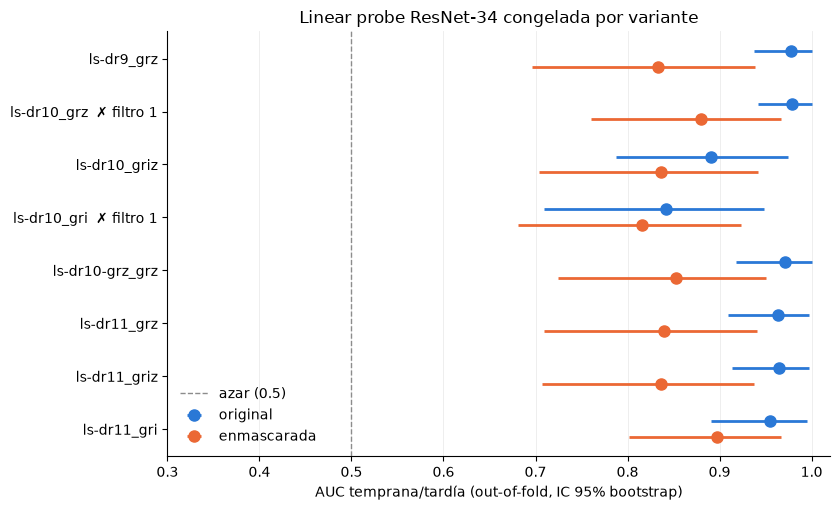

In [6]:
fig, ax = plt.subplots(figsize=(8.5, 5.2))
ypos = np.arange(len(variants))[::-1]
offsets = {"original": 0.15, "enmascarada": -0.15}
for entrada, color in INPUT_COLORS.items():
    part = results[results["entrada"] == entrada].set_index("variante").loc[variants]
    ax.errorbar(part["oof_auc"], ypos + offsets[entrada],
                xerr=[part["oof_auc"] - part["oof_ic_inf"], part["oof_ic_sup"] - part["oof_auc"]],
                fmt="o", markersize=8, color=color, ecolor=color, elinewidth=2, capsize=0, label=entrada)
ax.axvline(0.5, color="0.55", linewidth=1, linestyle="--", label="azar (0.5)")
ax.set_yticks(ypos, [f"{v}{'' if passes_filter_1[v] else '  ✗ filtro 1'}" for v in variants])
ax.set_xlim(0.3, 1.02)
ax.set_xlabel("AUC temprana/tardía (out-of-fold, IC 95% bootstrap)")
ax.grid(axis="x", alpha=0.25, linewidth=0.6)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.legend(loc="lower left", frameon=False)
ax.set_title("Linear probe ResNet-34 congelada por variante")
plt.tight_layout()
plt.show()

**Lectura de la figura (para no especialistas).** Cada renglón es una variante. El **punto** es su
AUC y la **línea horizontal** el rango plausible (intervalo de confianza del 95%): más corta = más
precisa. **Azul** = imagen original; **naranja** = enmascarada. La **línea punteada** en 0.5 es el
azar. "✗ filtro 1" marca las variantes que no pasaron el control de calidad.

**Qué se ve:**

1. **Todos los puntos están lejos de la línea del azar.** Cualquier variante permite distinguir
   tempranas de tardías mucho mejor que lanzar una moneda.
2. **El punto azul siempre está a la derecha del naranja.** Enmascarar empeora el resultado en
   todas las variantes, y las líneas naranjas son más largas (resultado menos preciso).
3. **Un grupo de cabeza casi empatado:** `ls-dr9_grz`, `ls-dr10_grz`, `ls-dr10-grz_grz`,
   `ls-dr11_grz`, `ls-dr11_griz` y `ls-dr11_gri` (original) tienen AUC ~0.96–0.98, y sus líneas se
   enciman casi por completo. Con 50 galaxias no se puede decir cuál es mejor.
4. **`ls-dr10_griz` y `ls-dr10_gri` quedan atrás** (AUC 0.89 y 0.84, con rangos mucho más anchos).

**Conclusión:** la imagen original de cualquiera de las variantes del grupo de cabeza funciona muy
bien. Lo que se puede descartar con esta muestra es la imagen enmascarada y las variantes DR10 con
banda *i*.

### 2.1 Comparación pareada contra la variante de referencia

Diferencia de AUC de cada dataset contra la referencia (`PROBE_REFERENCE_VARIANT`, la configuración
actual, imagen original), **sobre las mismas galaxias** (bootstrap pareado). Si el intervalo cruza
el 0, no hay evidencia de que una sea mejor que la otra con esta muestra.

**Términos de esta sección**

- **Bootstrap pareado:** como en el IC de la sección 2, se remuestrean las galaxias 2,000 veces,
  pero en cada remuestreo se usan **las mismas galaxias** para las dos variantes y se calcula la
  diferencia de AUC. Así se cancela el ruido de "qué galaxias tocaron" (unas son fáciles para
  todas las variantes) y solo queda la diferencia atribuible a la variante.
- **`dif_auc`:** AUC de la variante − AUC de la referencia (positiva = mejor que la referencia).
  En cada remuestreo $b$, con el mismo conjunto de galaxias $S_b$ para ambas:

  $$\Delta = \mathrm{AUC}_{A} - \mathrm{AUC}_{\text{ref}} \qquad
  \Delta^*_b = \mathrm{AUC}_{A}(S_b) - \mathrm{AUC}_{\text{ref}}(S_b), \quad b = 1,\dots,2000$$
- **`ic_inf`, `ic_sup`:** IC 95% de esa diferencia, por percentiles como en la sección 2:
  $\big[q_{2.5\%}\{\Delta^*_b\},\, q_{97.5\%}\{\Delta^*_b\}\big]$. Si contiene el 0, no se puede
  afirmar que una sea mejor.
- **`p_valor`:** fracción de remuestreos en los que la diferencia cambia de signo, multiplicada por
  2 (prueba bilateral: busca diferencias en cualquier dirección):

  $$p = \min\!\left(1,\; 2\cdot\min\!\left(\frac{\#\{b : \Delta^*_b \le 0\}}{B},\;
  \frac{\#\{b : \Delta^*_b \ge 0\}}{B}\right)\right), \qquad B = 2000$$

  p < 0.05 → la diferencia es
  **significativa**; p alto (p. ej. 0.6) → las dos variantes empatan con esta muestra. Un p alto no
  prueba que sean iguales, solo que 50 galaxias no alcanzan para distinguirlas.

In [7]:
reference = (PROBE_REFERENCE_VARIANT, "original")
paired = pd.DataFrame([
    {"variante": variant, "entrada": entrada,
     **paired_bootstrap_auc_diff(y, oof[(variant, entrada)], oof[reference])}
    for (variant, entrada) in oof if (variant, entrada) != reference
])
display(paired.set_index(["variante", "entrada"]).round(3))

dif_auc  ic_inf  ic_sup  p_valor
variante        entrada                                      
ls-dr9_grz      original      -0.002  -0.025   0.023    0.964
                enmascarada   -0.146  -0.269  -0.054    0.001
ls-dr10_grz     enmascarada   -0.099  -0.208  -0.018    0.011
ls-dr10_griz    original      -0.088  -0.178  -0.023    0.001
                enmascarada   -0.143  -0.258  -0.047    0.001
ls-dr10_gri     original      -0.138  -0.256  -0.046    0.001
                enmascarada   -0.163  -0.287  -0.063    0.000
ls-dr10-grz_grz original      -0.008  -0.037   0.012    0.589
                enmascarada   -0.126  -0.242  -0.040    0.002
ls-dr11_grz     original      -0.016  -0.050   0.008    0.254
                enmascarada   -0.139  -0.256  -0.050    0.001
ls-dr11_griz    original      -0.014  -0.049   0.013    0.335
                enmascarada   -0.142  -0.263  -0.051    0.000
ls-dr11_gri     original      -0.024  -0.083   0.016    0.283
                enmascarada   -0.082  -0.178  -0.011    0.017

**Lectura del resultado (para no especialistas).** Cada fila compara una versión contra la
**configuración actual del proyecto** (`ls-dr10_grz`, imagen original), **usando las mismas 50
galaxias**. Comparar galaxia por galaxia es más fino que comparar promedios: si unas galaxias son
fáciles para todas las variantes, esa ventaja se cancela.

- **`dif_auc`** negativo = peor que la referencia; positivo = mejor.
- Si el rango **`ic_inf` – `ic_sup` incluye el 0**, no hay diferencia demostrable (empate).
- **`p_valor` < 0.05** = la diferencia es real y no producto del azar.

**Qué dicen los números:**

- **Empatan con la referencia** (diferencia de −0.002 a −0.024, rango que incluye 0, p entre 0.25
  y 0.96): `ls-dr9_grz`, `ls-dr10-grz_grz`, `ls-dr11_grz`, `ls-dr11_griz` y `ls-dr11_gri`, en
  imagen original.
- **Claramente peores** (p ≤ 0.001): `ls-dr10_griz` (−0.09) y `ls-dr10_gri` (−0.14) en original.
- **Todas las enmascaradas son claramente peores** (−0.08 a −0.16, p ≤ 0.017).
- **Ninguna versión supera a la referencia** (todas las diferencias son ≤ 0).

**Conclusión:** cambiar de variante no mejora el rendimiento, pero cinco variantes rinden igual que
la actual **y además pasan el control de calidad**, cosa que la actual no hace. Se puede cambiar a
una de ellas sin perder rendimiento.

### 2.2 Matriz de confusión del mejor dataset

Obligatoria en cada experimento reportado (`README.md`, sección "Métricas de evaluación").
Predicciones *out-of-fold*, umbral 0.5.

**Matriz de confusión:** tabla 2×2 que cruza la clase real (filas) con la predicha (columnas). La
diagonal son los aciertos; fuera de ella, los dos tipos de error (tempranas llamadas tardías y
viceversa). Muestra *qué* clase se confunde, cosa que el AUC o la accuracy resumen en un solo
número. Se calcula con las predicciones *out-of-fold* y el umbral 0.5 (sección 2). Con *tardía*
como clase positiva (TP, TN, FP, FN definidos en la sección 2):

$$\begin{array}{c|cc}
 & \text{pred temprana} & \text{pred tardía} \\ \hline
\text{real temprana} & TN & FP \\
\text{real tardía} & FN & TP
\end{array}
\qquad
\mathrm{Accuracy} = \frac{TN + TP}{n}$$

In [8]:
eligible = results[results["variante"].map(passes_filter_1)]
best = eligible.sort_values("oof_auc", ascending=False).iloc[0]
best_key = (best["variante"], best["entrada"])
cm = confusion_matrix(y, (oof[best_key] >= 0.5).astype(int))
class_names = sorted(MORFOLOGIA_LABEL_TO_INT, key=MORFOLOGIA_LABEL_TO_INT.get)
print(f"Mejor dataset que pasa el filtro 1: {best_key[0]} ({best_key[1]}), AUC {best['oof_auc']:.3f}")
display(pd.DataFrame(cm, index=[f"real {c}" for c in class_names],
                     columns=[f"pred {c}" for c in class_names]))

Mejor dataset que pasa el filtro 1: ls-dr9_grz (original), AUC 0.978


,pred temprana,pred tardia
real temprana,24,1
real tardia,3,22


**Lectura del resultado (para no especialistas).** Entre las variantes que pasan el control de
calidad, la de mayor AUC es `ls-dr9_grz` con imagen original. La tabla cuenta sus aciertos y errores
(cada galaxia predicha por un modelo que no la vio al aprender):

- **Diagonal (aciertos):** 24 de 25 tempranas y 22 de 25 tardías bien clasificadas, **46 de 50 (92%)**.
- **Errores:** 1 temprana clasificada como tardía y **3 tardías clasificadas como tempranas**.

**Conclusión:** el modelo falla poco y casi siempre en la misma dirección: llama "tempranas" a
algunas tardías. Una hipótesis astronómica, **no verificada aquí**: podría tratarse de tardías de
transición (tipo Sa, con bulbo dominante) o de espirales con brazos débiles en estas imágenes.
Vale la pena que un astrónomo revise esas 3 galaxias y su `Ttype`. Si son casos frontera, el error
es razonable; si son espirales evidentes, apunta a un problema de la imagen o del modelo.

## 3. Rendimiento por región y generalización norte ↔ sur

La región del survey se puede adivinar desde la imagen en todas las variantes
(`notebook/image-curation.ipynb`, sección 6.3), aunque no está asociada a la clase. Aquí se
comprueba que eso no afecte al clasificador:

- **AUC por región** de las predicciones *out-of-fold* (modelo entrenado con ambas regiones);
- **entrenar en una región y evaluar en la otra**: si el AUC cae mucho respecto al de la validación
  cruzada mezclada, el modelo depende del telescopio y no solo de la morfología.

Con ~25 galaxias por región estos números son muy ruidosos: tomarlos como señal gruesa.

**Términos de esta sección**

- **`auc_oof_<región>`:** AUC (0.5 = azar, 1.0 = perfecto; ver sección 1.2) calculado solo con las
  predicciones *out-of-fold* (sección 2) de las galaxias de esa región. Si una región queda muy por
  debajo de la otra, el modelo funciona peor con ese telescopio. Es la fórmula del AUC de la
  sección 1.2 restringida a las galaxias de la región $R$:

  $$\mathrm{AUC}_R = \frac{1}{n_+^R\,n_-^R}\sum_{i\,\in\,\text{tardías}_R}\;\sum_{j\,\in\,\text{tempranas}_R}
  \Big[\mathbb{1}(\hat p_i^{\,\text{oof}} > \hat p_j^{\,\text{oof}}) + \tfrac{1}{2}\,\mathbb{1}(\hat p_i^{\,\text{oof}} = \hat p_j^{\,\text{oof}})\Big]$$
- **`auc_<entrena>→<evalua>`:** se entrena la regresión logística solo con galaxias de una región y
  se mide el AUC en las de la otra, que el modelo nunca vio. Es la prueba más dura de
  generalización: compararla con el AUC *out-of-fold* de la sección 2 (entrenado con ambas
  regiones mezcladas). Con $f_{N}$ el modelo entrenado solo con el norte:

  $$\mathrm{AUC}_{N\to S} = \mathrm{AUC}\big(\{y_i\}_{i\in S},\; \{f_N(\mathbf{x}_i)\}_{i\in S}\big)$$

  y análogo para $S \to N$.
- Aquí no hay IC ni p-valor: con ~25 galaxias por región serían tan anchos que no dirían nada.

In [9]:
region_rows = []
for (variant, entrada), X in embeddings.items():
    row = {"variante": variant, "entrada": entrada}
    for region in (LEGACY_REGION_NORTH, LEGACY_REGION_SOUTH):
        sel = regions == region
        row[f"auc_oof_{region}"] = bootstrap_auc_ci(y[sel], oof[(variant, entrada)][sel])["auc"]
    for cross in cross_group_auc(make_logistic_probe(), X, y, regions):
        row[f"auc_{cross['entrena']}→{cross['evalua']}"] = cross["auc"]
    region_rows.append(row)

by_region = pd.DataFrame(region_rows).set_index(["variante", "entrada"])
display(by_region.round(3))

auc_oof_norte  auc_oof_sur  auc_norte→sur  \
variante        entrada                                                  
ls-dr9_grz      original             1.000        0.962          0.978   
                enmascarada          0.818        0.841          0.896   
ls-dr10_grz     original             0.992        0.956          1.000   
                enmascarada          0.856        0.901          0.813   
ls-dr10_griz    original             0.970        0.824          0.824   
                enmascarada          0.871        0.821          0.901   
ls-dr10_gri     original             0.932        0.742          0.819   
                enmascarada          0.848        0.791          0.846   
ls-dr10-grz_grz original             0.992        0.951          0.984   
                enmascarada          0.841        0.857          0.896   
ls-dr11_grz     original             0.985        0.940          0.967   
                enmascarada          0.803        0.846          0.896   
ls-dr11_griz    original             0.977        0.951          0.962   
                enmascarada          0.803        0.907          0.934   
ls-dr11_gri     original             0.970        0.934          0.956   
                enmascarada          0.879        0.945          0.967   

                             auc_sur→norte  
variante        entrada                     
ls-dr9_grz      original             1.000  
                enmascarada          0.879  
ls-dr10_grz     original             0.985  
                enmascarada          0.894  
ls-dr10_griz    original             0.939  
                enmascarada          0.909  
ls-dr10_gri     original             0.947  
                enmascarada          0.833  
ls-dr10-grz_grz original             0.970  
                enmascarada          0.886  
ls-dr11_grz     original             0.955  
                enmascarada          0.864  
ls-dr11_griz    original             0.939  
                enmascarada          0.886  
ls-dr11_gri     original             0.970  
                enmascarada          0.909

**Lectura del resultado (para no especialistas).** Las galaxias del **norte** las observaron
BASS/MzLS (Kitt Peak) y las del **sur** DECam (Chile): cámaras, filtros y profundidad distintos. Aquí
se comprueba que el modelo reconoce la **morfología** y no el **telescopio**:

- **`auc_oof_norte` / `auc_oof_sur`:** AUC calculado solo con las galaxias de cada región (el modelo
  aprendió con ambas). Si una región queda muy abajo, el modelo funciona peor con ese telescopio.
- **`auc_norte→sur`:** el modelo aprende **solo con galaxias del norte** y se califica con las del
  sur, que nunca vio. **`auc_sur→norte`** es lo inverso. Es la prueba más exigente: si el modelo
  dependiera del telescopio, aquí se desplomaría.

**Qué dicen los números (imagen original):**

- **Variantes del grupo de cabeza** (`ls-dr9_grz`, `ls-dr10_grz`, `ls-dr10-grz_grz`, `ls-dr11_*`):
  AUC 0.93–1.00 en ambas regiones y 0.94–1.00 al cruzar de una región a la otra. Lo aprendido con
  un telescopio funciona con el otro.
- **`ls-dr10_griz` y `ls-dr10_gri`** caen en el sur (AUC 0.82 y 0.74) y al pasar del norte al sur
  (0.82). En DR10 la banda *i* solo existe para DECam (sur), así que estas imágenes se construyen
  distinto según la región y el modelo lo resiente.

**Cautela:** con ~25 galaxias por región, una o dos galaxias mal ordenadas mueven el AUC varias
centésimas. Solo las caídas grandes, como las de DR10 con banda *i*, son señal clara.

**Conclusión:** las buenas variantes generalizan entre telescopios. Las variantes DR10 con banda *i*
no lo hacen, lo que confirma que conviene descartarlas.

## 4. Resumen

Una fila por dataset (variante × entrada). Cómo leerla:

1. Descartar lo que **no pasa el filtro 1** (calidad / color heterogéneo entre regiones).
2. En la versión **enmascarada**, desconfiar si el AUC de la silueta sola se acerca al del
   clasificador: el modelo podría estar usando el contorno.
3. Entre lo que queda, preferir el **AUC más alto**, pero solo declarar ganadora una variante si su
   diferencia contra las demás es significativa (sección 2.1); si empatan, preferir la de render más
   homogéneo y simple.
4. Revisar que el rendimiento no se desplome **entre regiones** (sección 3).

**Columnas de la tabla**

- `oof_auc`, `oof_ic_inf`, `oof_ic_sup`: AUC *out-of-fold* y su IC 95% bootstrap (sección 2).
  AUC 0.5 = azar, 1.0 = perfecto.
  $\mathrm{AUC} = \frac{1}{n_+ n_-}\sum_{i,j}\big[\mathbb{1}(\hat p_i > \hat p_j) + \tfrac12\mathbb{1}(\hat p_i = \hat p_j)\big]$;
  IC $= [q_{2.5\%}, q_{97.5\%}]$ de los AUC bootstrap.
- `f1_macro`: F1 promedio de las dos clases con umbral 0.5 (sección 2):
  $F_1^{\text{macro}} = \tfrac12\big(F_1^{\text{temprana}} + F_1^{\text{tardía}}\big)$, con
  $F_1 = \frac{2\,TP}{2\,TP + FP + FN}$ por clase.
- `pasa_filtro_1`: si la variante pasa el filtro de calidad / color (`notebook/image-curation.ipynb`).
- `auc_silueta_sola`: AUC de la silueta 32×32 sola (sección 1.2); cerca de 0.5 = sin atajo.
- `dif_vs_ref`, `p_vs_ref`: diferencia de AUC contra la referencia y su p-valor del bootstrap
  pareado (sección 2.1); p < 0.05 = diferencia significativa.
  $\Delta = \mathrm{AUC}_A - \mathrm{AUC}_{\text{ref}}$,
  $p = \min\big(1, 2\min(\Pr^*[\Delta^* \le 0], \Pr^*[\Delta^* \ge 0])\big)$.
- `auc_norte→sur`, `auc_sur→norte`: AUC entrenando en una región y evaluando en la otra (sección 3).

In [10]:
silhouette_auc = mask_shortcut[mask_shortcut["representacion"] == "silueta 32x32"].set_index("variante")["auc_media"]
summary = results.set_index(["variante", "entrada"])[["oof_auc", "oof_ic_inf", "oof_ic_sup", "f1_macro"]].copy()
summary["pasa_filtro_1"] = summary.index.get_level_values("variante").map(passes_filter_1)
summary["auc_silueta_sola"] = summary.index.get_level_values("variante").map(silhouette_auc)
summary["dif_vs_ref"] = paired.set_index(["variante", "entrada"])["dif_auc"]
summary["p_vs_ref"] = paired.set_index(["variante", "entrada"])["p_valor"]
summary["auc_norte→sur"] = by_region[f"auc_{LEGACY_REGION_NORTH}→{LEGACY_REGION_SOUTH}"]
summary["auc_sur→norte"] = by_region[f"auc_{LEGACY_REGION_SOUTH}→{LEGACY_REGION_NORTH}"]
display(summary.sort_values("oof_auc", ascending=False).round(3))

oof_auc  oof_ic_inf  oof_ic_sup  f1_macro  \
variante        entrada                                                  
ls-dr10_grz     original       0.979       0.942       1.000     0.919   
ls-dr9_grz      original       0.978       0.937       1.000     0.920   
ls-dr10-grz_grz original       0.971       0.918       1.000     0.920   
ls-dr11_griz    original       0.965       0.913       0.997     0.879   
ls-dr11_grz     original       0.963       0.909       0.997     0.879   
ls-dr11_gri     original       0.955       0.890       0.995     0.880   
                enmascarada    0.898       0.801       0.966     0.820   
ls-dr10_griz    original       0.891       0.787       0.974     0.819   
ls-dr10_grz     enmascarada    0.880       0.760       0.966     0.778   
ls-dr10-grz_grz enmascarada    0.853       0.724       0.950     0.800   
ls-dr10_gri     original       0.842       0.709       0.948     0.840   
ls-dr11_grz     enmascarada    0.840       0.710       0.941     0.760   
ls-dr11_griz    enmascarada    0.837       0.707       0.938     0.760   
ls-dr10_griz    enmascarada    0.836       0.704       0.942     0.780   
ls-dr9_grz      enmascarada    0.834       0.696       0.938     0.800   
ls-dr10_gri     enmascarada    0.816       0.681       0.923     0.740   

                             pasa_filtro_1  auc_silueta_sola  dif_vs_ref  \
variante        entrada                                                    
ls-dr10_grz     original             False             0.494         NaN   
ls-dr9_grz      original              True             0.566      -0.002   
ls-dr10-grz_grz original              True             0.547      -0.008   
ls-dr11_griz    original              True             0.445      -0.014   
ls-dr11_grz     original              True             0.550      -0.016   
ls-dr11_gri     original              True             0.475      -0.024   
                enmascarada           True             0.475      -0.082   
ls-dr10_griz    original              True             0.499      -0.088   
ls-dr10_grz     enmascarada          False             0.494      -0.099   
ls-dr10-grz_grz enmascarada           True             0.547      -0.126   
ls-dr10_gri     original             False             0.538      -0.138   
ls-dr11_grz     enmascarada           True             0.550      -0.139   
ls-dr11_griz    enmascarada           True             0.445      -0.142   
ls-dr10_griz    enmascarada           True             0.499      -0.143   
ls-dr9_grz      enmascarada           True             0.566      -0.146   
ls-dr10_gri     enmascarada          False             0.538      -0.163   

                             p_vs_ref  auc_norte→sur  auc_sur→norte  
variante        entrada                                              
ls-dr10_grz     original          NaN          1.000          0.985  
ls-dr9_grz      original        0.964          0.978          1.000  
ls-dr10-grz_grz original        0.589          0.984          0.970  
ls-dr11_griz    original        0.335          0.962          0.939  
ls-dr11_grz     original        0.254          0.967          0.955  
ls-dr11_gri     original        0.283          0.956          0.970  
                enmascarada     0.017          0.967          0.909  
ls-dr10_griz    original        0.001          0.824          0.939  
ls-dr10_grz     enmascarada     0.011          0.813          0.894  
ls-dr10-grz_grz enmascarada     0.002          0.896          0.886  
ls-dr10_gri     original        0.001          0.819          0.947  
ls-dr11_grz     enmascarada     0.001          0.896          0.864  
ls-dr11_griz    enmascarada     0.000          0.934          0.886  
ls-dr10_griz    enmascarada     0.001          0.901          0.909  
ls-dr9_grz      enmascarada     0.001          0.896          0.879  
ls-dr10_gri     enmascarada     0.000          0.846          0.833

**Lectura del resultado (para no especialistas).** Es la tabla final, ordenada de mayor a menor AUC.
Para elegir variante, una fila debe cumplir **todo** lo siguiente:

1. `pasa_filtro_1 = True` (control de calidad);
2. `oof_auc` alto (cerca de 1);
3. `auc_silueta_sola` cerca de 0.5 (el contorno solo no delata la clase);
4. `p_vs_ref` alto, es decir, que no sea peor que la referencia;
5. `auc_norte→sur` y `auc_sur→norte` altos (funciona con ambos telescopios).

**Qué se ve:**

- **Las 6 primeras filas son todas de imagen original.** Todas las enmascaradas quedan abajo.
- **La primera fila (`ls-dr10_grz`, la configuración actual) no pasa el filtro de calidad.** Rinde
  muy bien, pero colorea distinto el norte y el sur, y se descarta por precaución.
- **Las siguientes cinco** (`ls-dr9_grz`, `ls-dr10-grz_grz`, `ls-dr11_griz`, `ls-dr11_grz`,
  `ls-dr11_gri`) **cumplen los 5 criterios**: AUC 0.955–0.978, empate con la referencia (p ≥ 0.25),
  silueta sola sin poder predictivo (0.45–0.57) y AUC ≥ 0.94 al cruzar entre regiones.

**Conclusión:** hay varias variantes igual de buenas. Con 50 galaxias no hay un ganador único; la
elección final entre ellas necesita más galaxias o un criterio astronómico (ver abajo).

## Observaciones (muestra de 50, 2026-10-07)

**Atajo de la máscara: moderado y en buena parte legítimo.**
- La **silueta 32×32** no predice la clase en ninguna variante (AUC 0.45–0.57, p > 0.05).
- Los **4 descriptores de forma** sí, de forma moderada (AUC 0.60–0.71; significativo con p ≤ 0.04
  en `ls-dr9_grz`, `ls-dr10-grz_grz` y `ls-dr11_grz`). Los mueven sobre todo la **elongación**
  (tardías 0.34 vs. tempranas 0.22) y el **área** (0.25 vs. 0.28). La elongación es información
  morfológica real (un disco inclinado se ve alargado), no un artefacto del recorte.
- El clasificador sobre imagen enmascarada (AUC 0.82–0.90) supera a la forma sola (≤ 0.71): usa
  más que el contorno. Vigilar el área de la máscara con la muestra ampliada.

**Enmascarar empeora el clasificador en todas las variantes.** Contra la referencia, la versión
enmascarada pierde entre 0.08 y 0.16 de AUC, y la diferencia es significativa en todas (p ≤ 0.02).
Causas probables: la máscara quita disco externo, brazos y entorno, y el fondo negro con borde duro
es una imagen muy distinta a las de ImageNet. Con este backbone congelado, la máscara dura no
conviene para entrenar; alternativas a probar: fondo relleno con ruido de cielo o borde suavizado,
o usar la máscara solo para borrar estrellas y conservar el resto.

**Imagen original: cinco variantes empatadas arriba.** `ls-dr9_grz` (0.978), `ls-dr10-grz_grz`
(0.971), `ls-dr11_griz` (0.965), `ls-dr11_grz` (0.963) y `ls-dr11_gri` (0.955) no se distinguen de
la referencia (p entre 0.25 y 0.96). Un AUC ~0.96–0.98 está en el rango de la literatura para el
problema binario.

**`ls-dr10_griz` y `ls-dr10_gri` son significativamente peores** (−0.09 y −0.14, p = 0.001) y caen
justo en el sur (AUC 0.82 y 0.74; entrenando en el norte y evaluando en el sur, 0.82). En DR10 la
banda *i* solo existe en la región DECam, así que esos renders cambian según la región. La prueba
entre regiones detecta en `ls-dr10_griz` lo que el filtro 1 dejó pasar.

**`ls-dr10_grz` (la actual) rinde igual que las mejores** (0.979, y 1.00 / 0.985 entre regiones)
pese al tono morado del sur, porque la región no está asociada a la clase. Queda excluida por el
filtro 1 por precaución (dos dominios de color), no porque rinda peor: con 50 galaxias no se puede
demostrar daño.

**Siguiente paso.** Las finalistas son `ls-dr9_grz`, `ls-dr10-grz_grz`, `ls-dr11_grz` y
`ls-dr11_griz` (imagen original). Para separarlas, ampliar la muestra
(`python -m src.data.download_cutouts --variants ls-dr9_grz ls-dr10-grz_grz ls-dr11_grz ls-dr11_griz ls-dr10_grz --n 2000`)
y volver a ejecutar las dos libretas. El desacuerdo DR9 vs. DR11 (Héctor/José) no se resuelve con
rendimiento: en esta muestra empatan.

## Conclusiones en términos simples

1. **Las imágenes de Legacy Survey contienen suficiente información para separar tempranas de
   tardías.** Una red neuronal que nunca vio una galaxia, combinada con una fórmula simple, logra
   AUC ~0.96–0.98 y acierta ~88–92% de las 50 galaxias. El rango esperado en la literatura para
   esta tarea es ~94.5–99% de aciertos (`README.md`, sección "Métricas de evaluación"), y aquí
   todavía no se entrenó la red con galaxias, así que es un buen punto de partida.

2. **No conviene usar la máscara dura (fondo negro) para entrenar.** Empeora el resultado en todas
   las variantes. Probablemente borra información útil (disco externo, brazos tenues, entorno) y
   produce imágenes muy distintas a las que conoce la red.

3. **El contorno de la máscara no es un "atajo" preocupante.** Solo da una pista débil (AUC ≤ 0.71),
   que viene sobre todo de la elongación, una propiedad morfológica real.

4. **Varias variantes empatan arriba:** `ls-dr9_grz`, `ls-dr10-grz_grz`, `ls-dr11_grz` y
   `ls-dr11_griz` (las finalistas, ver "Observaciones"). Todas pasan el control de calidad,
   funcionan igual con los telescopios del norte y del sur, y rinden igual que la configuración
   actual.

5. **Evitar DR10 con banda *i* (`ls-dr10_griz`, `ls-dr10_gri`).** La banda *i* solo existe en el
   sur, así que la imagen cambia según el telescopio y el rendimiento cae en el sur.

6. **Limitación principal: 50 galaxias.** Alcanza para descartar opciones malas, no para elegir
   entre opciones casi iguales. El siguiente paso es repetir el análisis con ~2,000 galaxias.

**Preguntas abiertas para el equipo de astronomía:**

- Como DR9 y DR11 rinden igual, ¿hay razones astronómicas (profundidad, calibración, cobertura,
  procesamiento) para preferir una de ellas?
- ¿Las 3 tardías que el modelo confunde con tempranas (sección 2.2) son casos frontera, por ejemplo
  de tipo Sa con bulbo dominante?
- Si en el futuro se quiere aislar la galaxia central, ¿qué alternativa a la máscara dura sería más
  aceptable desde el punto de vista astronómico: rellenar el fondo con ruido de cielo, suavizar el
  borde o borrar solo las estrellas?